<!-- Projeto Desenvolvido na Data Science Academy - www.datascienceacademy.com.br -->
# <font color='blue'>Data Science Academy</font>
## <font color='blue'>Matemática e Estatística Aplicada Para Data Science, Machine Learning e IA</font>
## <font color='blue'>Lab 7</font>
### <font color='blue'>Distribuições de Probabilidade de Variáveis Aleatórias Discretas</font>

## Instalando e Carregando os Pacotes

In [1]:
# Para atualizar um pacote, execute o comando abaixo no terminal ou prompt de comando:
# pip install -U nome_pacote

# Para instalar a versão exata de um pacote, execute o comando abaixo no terminal ou prompt de comando:
# !pip install nome_pacote==versão_desejada

# Depois de instalar ou atualizar o pacote, reinicie o jupyter notebook.

# Instala o pacote watermark. 
# Esse pacote é usado para gravar as versões de outros pacotes usados neste jupyter notebook.
!pip install -q -U watermark

In [2]:
# Imports
import scipy
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.stats import poisson
from scipy.stats import geom
from scipy.stats import nbinom
from scipy.stats import hypergeom

In [3]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Data Science Academy" 

Author: Data Science Academy



## Distribuições de Probabilidade como Ferramentas de Análise

As distribuições de probabilidade de variáveis aleatórias discretas são ferramentas de análise que nos ajudam a entender e quantificar a incerteza em processos ou experimentos que resultam em resultados contáveis. Elas fornecem uma maneira de calcular a probabilidade de ocorrência de cada possível resultado de uma variável aleatória discreta.

As distribuições de probabilidade de variáveis aleatórias discretas descrevem a probabilidade de ocorrência de cada valor de uma variável aleatória que assume valores discretos. 

Aqui estão algumas maneiras pelas quais essas distribuições podem ser usadas como ferramentas de análise:

**Descrever a distribuição**: Elas nos permitem descrever a distribuição dos resultados possíveis de um experimento ou processo, especificando a probabilidade de cada resultado.

**Calcular probabilidades**: Podemos usar as distribuições para calcular a probabilidade de diferentes eventos, como a probabilidade de um resultado específico ou a probabilidade de um resultado estar dentro de um intervalo específico.

**Medir tendência central e dispersão**: As distribuições permitem calcular medidas como a média (ou esperança matemática), que indica a tendência central, e a variância ou desvio padrão, que indicam a dispersão ou variabilidade dos resultados.

**Realizar inferências estatísticas**: Podemos usar essas distribuições para realizar testes de hipóteses e construir intervalos de confiança, ajudando a tomar decisões com base em dados.

**Modelagem e simulação**: As distribuições de probabilidade são frequentemente usadas para modelar fenômenos reais em diversas áreas, como finanças, engenharia e ciências sociais. Elas também são usadas em simulações computacionais para gerar dados que imitam o comportamento de sistemas reais.

### Distribuição Uniforme Discreta

Nesta distribuição, todos os n valores de uma variável têm aproximadamente a mesma probabilidade de ocorrer. Por exemplo, o lançamento de um dado justo.

Vamos simular o lançamento de um dado justo, que é um caso clássico de distribuição uniforme discreta, onde cada face do dado (de 1 a 6) tem igual probabilidade de sair.

In [9]:
# Define o número de lançamentos
n_lancamentos = 1000

# Gera n_lancamentos de números aleatórios entre 1 e 6
lancamentos = np.random.randint(1, 7, size = n_lancamentos)

# Calcula e imprime a frequência de cada resultado
for i in range(1, 7):
    frequencia = np.sum(lancamentos == i)
    print(f"Face {i}: {frequencia} vezes ({frequencia / n_lancamentos * 100:.2f}%)")

Face 1: 175 vezes (17.50%)
Face 2: 163 vezes (16.30%)
Face 3: 165 vezes (16.50%)
Face 4: 178 vezes (17.80%)
Face 5: 155 vezes (15.50%)
Face 6: 164 vezes (16.40%)


No código acima, **np.random.randint(1, 7, size = n_lancamentos)** gera uma amostra de n_lancamentos de valores inteiros de 1 a 6, simulando o lançamento de um dado justo em n_lancamentos vezes. Em seguida, o código conta e imprime a frequência de cada face do dado aparecendo nos lançamentos, junto com a porcentagem que essa frequência representa em relação ao total de lançamentos. Este exemplo ilustra bem o conceito de distribuição uniforme discreta, onde cada resultado tem aproximadamente a mesma probabilidade de ocorrer.

Vamos criar um plot.

In [14]:
# Calcula a frequência de cada resultado
frequencias = [np.sum(lancamentos == i) for i in range(1, 7)]

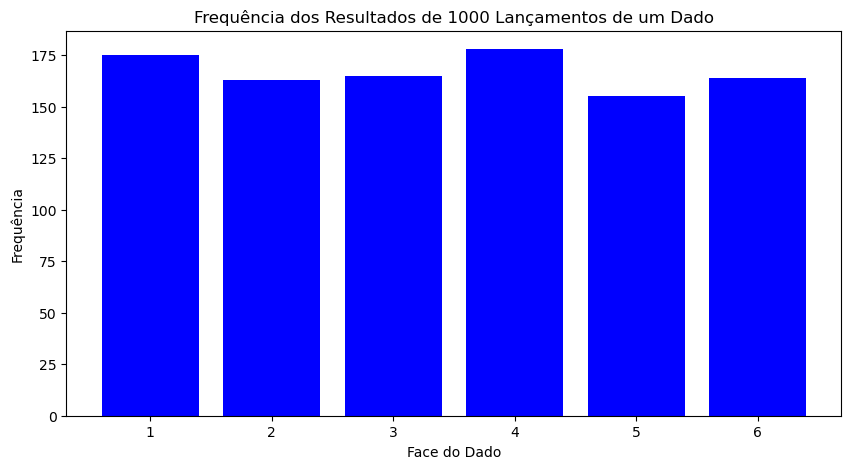

In [15]:
# Cria um gráfico de barras para mostrar a frequência de cada face
plt.figure(figsize = (10, 5))
faces = range(1, 7)
plt.bar(faces, frequencias, color = 'blue')
plt.xlabel('Face do Dado')
plt.ylabel('Frequência')
plt.title('Frequência dos Resultados de 1000 Lançamentos de um Dado')
plt.xticks(faces)
plt.show()

### Distribuição Binomial

Descreve o número de sucessos em n ensaios independentes de Bernoulli (experimentos com dois possíveis resultados, como sucesso e fracasso) com a mesma probabilidade de sucesso p. Por exemplo, o número de caras em 10 lançamentos de uma moeda.

O exemplo abaixo simula um cenário comum de lançamento de moeda, onde estamos interessados em encontrar a probabilidade de obter um determinado número de caras (sucesso) em um número fixo de lançamentos.

Imagine que você lança uma moeda justa 10 vezes e quer saber a probabilidade de obter exatamente 5 caras. A moeda justa significa que a probabilidade de cara (sucesso) é de 0,5 em cada lançamento.

In [33]:
# Define os parâmetros da distribuição binomial

# Número de ensaios (lançamentos da moeda)
n = 10  

# Probabilidade de sucesso (cara) em cada ensaio
p = 0.5

# Calcula a probabilidade de obter exatamente 5 sucessos (caras)
probabilidade = binom.pmf(5, n, p)

print(f"\nA probabilidade de obter exatamente 5 caras em 10 lançamentos é de {probabilidade * 100:.2f}%")


A probabilidade de obter exatamente 5 caras em 10 lançamentos é de 24.61%


No código acima, **binom.pmf(k, n, p)** calcula a função de massa de probabilidade (probability mass function - pmf) da distribuição binomial, que é a probabilidade de obter k sucessos em n ensaios independentes, cada um com probabilidade de sucesso p. O resultado é a probabilidade de obter exatamente 5 caras (sucessos) quando você lança uma moeda justa 10 vezes.

Vamos criar o plot.

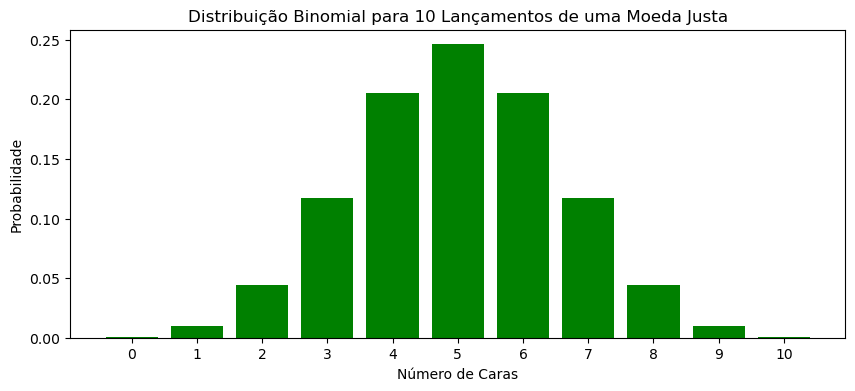

In [34]:
# Gera um gráfico da distribuição binomial
plt.figure(figsize = (10, 4))
x = range(n + 1)
y = binom.pmf(x, n, p)
plt.bar(x, y, color = 'green')
plt.xlabel('Número de Caras')
plt.ylabel('Probabilidade')
plt.title('Distribuição Binomial para 10 Lançamentos de uma Moeda Justa')
plt.xticks(x)
plt.show()

### Distribuição de Poisson

Usada para modelar o número de vezes que um evento acontece em um intervalo de tempo ou espaço fixo, quando esses eventos ocorrem com uma taxa média constante e independente do tempo desde o último evento. Por exemplo, o número de chamadas recebidas por um call center em uma hora.

Suponha que queremos modelar o número de chamadas que um call center recebe em uma hora. Se a taxa média de chamadas é de 10 chamadas por hora, podemos usar a distribuição de Poisson para calcular a probabilidade de receber um determinado número de chamadas, digamos 15, em uma hora.

In [35]:
# Define a taxa média de chamadas por hora
lambda_ = 10  # 'lambda' é a taxa média de eventos (chamadas) por intervalo (hora)

# Calcula a probabilidade de receber exatamente 15 chamadas em uma hora
probabilidade = poisson.pmf(15, lambda_)

print(f"\nA probabilidade de receber exatamente 15 chamadas em uma hora é de {probabilidade * 100:.2f}%")


A probabilidade de receber exatamente 15 chamadas em uma hora é de 3.47%


No código acima, **poisson.pmf(k, lambda_)** calcula a função de massa de probabilidade da distribuição de Poisson, que é a probabilidade de ocorrer k eventos em um intervalo fixo, dado uma taxa média de eventos lambda_ por intervalo. O resultado nos dá a probabilidade de receber exatamente 15 chamadas em uma hora, dado que a taxa média é de 10 chamadas por hora.

Vamos criar o plot.

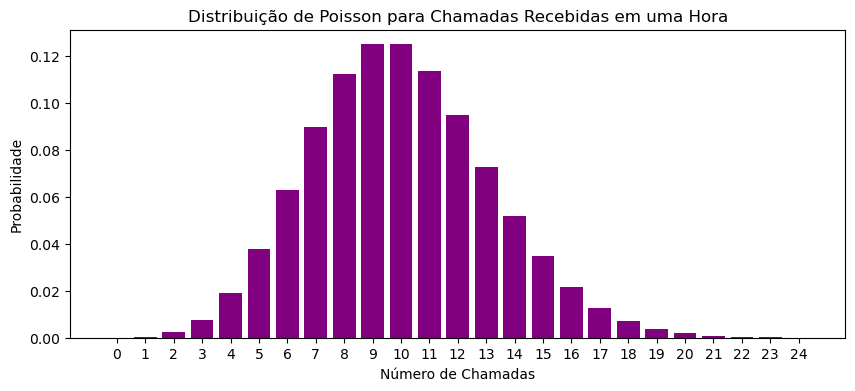

In [36]:
# Gera um gráfico da distribuição de Poisson
plt.figure(figsize = (10, 4))
x = range(0, 25)  # Define um intervalo de valores possíveis para o número de chamadas
y = poisson.pmf(x, lambda_)
plt.bar(x, y, color = 'purple')
plt.xlabel('Número de Chamadas')
plt.ylabel('Probabilidade')
plt.title('Distribuição de Poisson para Chamadas Recebidas em uma Hora')
plt.xticks(x)
plt.show()

### Distribuição Geométrica

Modela o número de ensaios de Bernoulli necessários para obter o primeiro sucesso. Por exemplo, o número de lançamentos de uma moeda até que saia cara pela primeira vez.

A distribuição geométrica modela o número de ensaios de Bernoulli (experimentos com dois possíveis resultados, sucesso ou fracasso) necessários para obter o primeiro sucesso, assumindo que a probabilidade de sucesso em cada ensaio é constante.

Por exemplo, consideremos o lançamento repetido de uma moeda justa, onde estamos interessados na probabilidade de que o primeiro "cara" (sucesso) ocorra no quinto lançamento. A probabilidade de sucesso (obter "cara") em cada lançamento é de 0.5.

In [37]:
# Define a probabilidade de sucesso em cada ensaio
p = 0.5  # Probabilidade de cara

# Calcula a probabilidade de o primeiro sucesso ocorrer no 5º lançamento
probabilidade = geom.pmf(5, p)

print(f"\nA probabilidade de o primeiro 'cara' ocorrer no 5º lançamento é de {probabilidade * 100:.2f}%")


A probabilidade de o primeiro 'cara' ocorrer no 5º lançamento é de 3.12%


Neste código, geom.pmf(k, p) calcula a função de massa de probabilidade para a distribuição geométrica, que é a probabilidade de que o primeiro sucesso ocorra no k-ésimo ensaio, dado que a probabilidade de sucesso em cada ensaio é p. O resultado nos dá a probabilidade de que o primeiro "cara" apareça especificamente no quinto lançamento de uma moeda.

Vamos criar o plot.

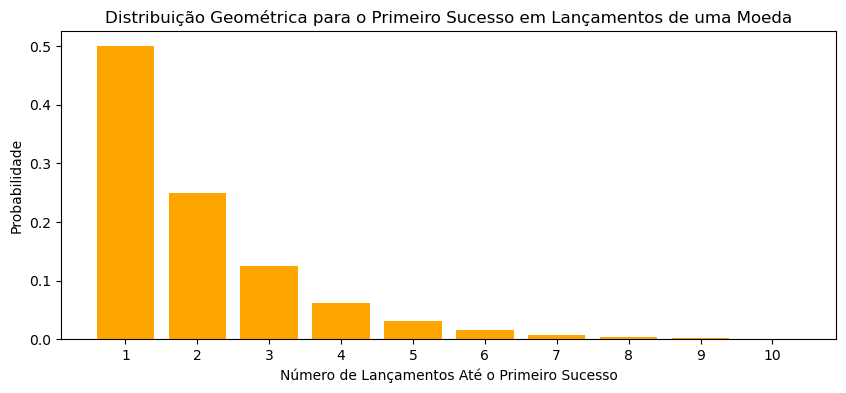

In [38]:
# Gera um gráfico da distribuição geométrica
plt.figure(figsize = (10, 4))
x = range(1, 11)  # Define um intervalo de valores possíveis para o número de lançamentos até o primeiro sucesso
y = geom.pmf(x, p)
plt.bar(x, y, color = 'orange')
plt.xlabel('Número de Lançamentos Até o Primeiro Sucesso')
plt.ylabel('Probabilidade')
plt.title('Distribuição Geométrica para o Primeiro Sucesso em Lançamentos de uma Moeda')
plt.xticks(x)
plt.show()

### Distribuição Binomial Negativa

Generalização da distribuição geométrica, essa distribuição modela o número de ensaios de Bernoulli necessários para alcançar um número específico de sucessos. Por exemplo, o número de lançamentos de uma moeda até que saia cara três vezes.

A distribuição binomial negativa modela o número de ensaios de Bernoulli (com dois resultados possíveis: sucesso ou fracasso) necessários para alcançar um determinado número de sucessos, com a probabilidade de sucesso sendo constante em cada ensaio.

Por exemplo, considere um experimento onde você está lançando uma moeda justa e quer saber a probabilidade de que seja necessário realizar 10 lançamentos para obter 3 caras (sucessos). A probabilidade de cara (sucesso) em cada lançamento é de 0.5.

In [57]:
# Define os parâmetros da distribuição binomial negativa

# Número de sucessos desejados
r = 3  

# Probabilidade de sucesso em cada ensaio
p = 0.5  

# Calcula a probabilidade de que sejam necessários 10 lançamentos para obter 3 sucessos
prob = nbinom.pmf(10-r, r, p)

print(f"\nA probabilidade de que sejam necessários 10 lançamentos para obter 3 caras é de {prob * 100:.2f}%")


A probabilidade de que sejam necessários 10 lançamentos para obter 3 caras é de 3.52%


Neste exemplo, usamos nbinom.pmf(k, r, p) para calcular a função de massa de probabilidade da distribuição binomial negativa. Aqui, k é o número total de ensaios menos o número de sucessos (10 - 3 neste caso, porque queremos saber a probabilidade de que os três sucessos ocorram nos primeiros 10 ensaios), r é o número de sucessos desejados, e p é a probabilidade de sucesso em cada ensaio. O resultado representa a probabilidade de precisar de exatamente 10 lançamentos para obter 3 sucessos.

Vamos criar o plot.

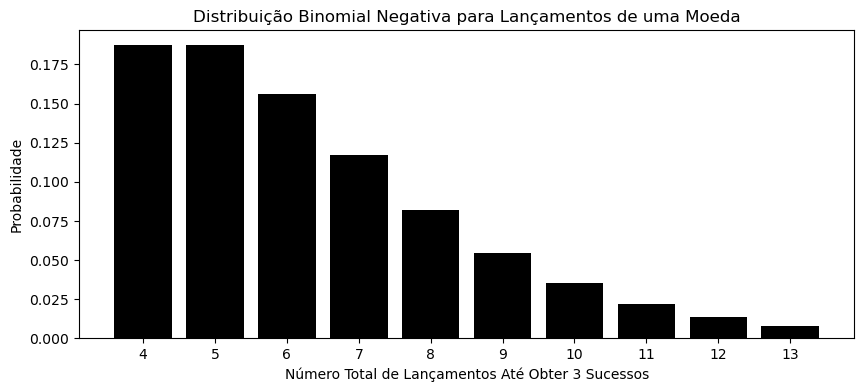

In [68]:
# Plot
plt.figure(figsize = (10, 4))
x_total = [i + r for i in x]
y=[nbinom.pmf(i-r, r, p) for i in x_total]
plt.bar(x_total, y, color = 'black')
plt.xlabel('Número Total de Lançamentos Até Obter 3 Sucessos')
plt.ylabel('Probabilidade')
plt.title('Distribuição Binomial Negativa para Lançamentos de uma Moeda')
plt.xticks(x_total)
plt.show()

### Distribuição Hipergeométrica

Modela o número de sucessos em amostras retiradas sem reposição de uma população finita que contém um número fixo de sucessos e fracassos. Por exemplo, o número de cartas vermelhas retiradas em uma mão de 5 cartas de um baralho padrão de 52 cartas.

A distribuição hipergeométrica descreve a probabilidade de obter um determinado número de sucessos em amostras retiradas sem reposição de uma população finita que consiste em dois tipos de objetos, sucessos e fracassos.

Imagine um cenário onde temos um baralho de 52 cartas, das quais 26 são vermelhas (sucessos) e 26 são pretas (fracassos). Você quer saber a probabilidade de retirar exatamente 5 cartas vermelhas ao escolher 10 cartas aleatoriamente do baralho, sem reposição.

In [69]:
# Define os parâmetros da distribuição hipergeométrica

# Tamanho total da população (baralho de cartas)
M = 52  

# Total de sucessos na população (cartas vermelhas)
n = 26  

# Tamanho da amostra (número de cartas retiradas)
N = 10  

# Calcula a probabilidade de obter exatamente 5 sucessos (cartas vermelhas) na amostra
prob = hypergeom.pmf(5, M, n, N)

print(f"\nA probabilidade de retirar exatamente 5 cartas vermelhas ao escolher 10 cartas é de {prob * 100:.2f}%")


A probabilidade de retirar exatamente 5 cartas vermelhas ao escolher 10 cartas é de 27.35%


Neste código, hypergeom.pmf(k, M, n, N) calcula a função de massa de probabilidade da distribuição hipergeométrica, onde k é o número de sucessos desejados na amostra (5 cartas vermelhas), M é o tamanho total da população (52 cartas), n é o número total de sucessos na população (26 cartas vermelhas), e N é o tamanho da amostra (10 cartas retiradas). O resultado nos dá a probabilidade de retirar exatamente 5 cartas vermelhas de um baralho de 52 cartas ao escolher 10 cartas sem reposição.

Vamos criar o plot.

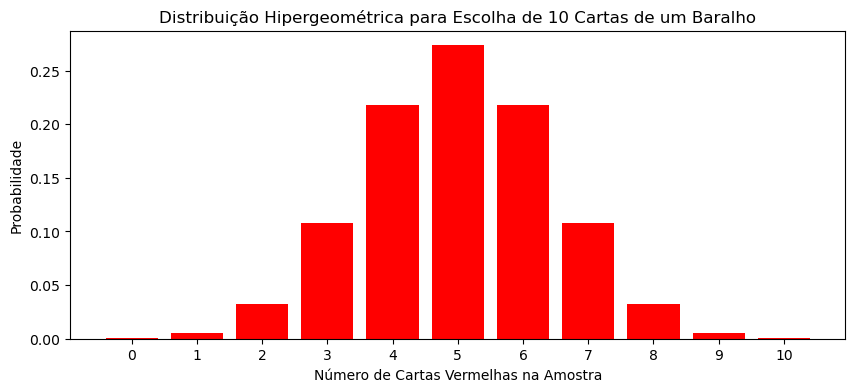

In [71]:
# Plot
plt.figure(figsize = (10, 4))
x = range(0, 11)  # Define um intervalo de valores possíveis para o número de sucessos na amostra
y = hypergeom.pmf(x, M, n, N)
plt.bar(x, y, color = 'red')
plt.xlabel('Número de Cartas Vermelhas na Amostra')
plt.ylabel('Probabilidade')
plt.title('Distribuição Hipergeométrica para Escolha de 10 Cartas de um Baralho')
plt.xticks(x)
plt.show()

## Conclusão

Uma distribuição de probabilidade é uma função estatística que descreve todos os valores e probabilidades possíveis que uma variável aleatória pode assumir dentro de um determinado intervalo. Este intervalo será limitado entre os valores mínimo e máximo possíveis, mas precisamente onde o valor possível provavelmente será traçado na distribuição de probabilidade depende de uma série de fatores. 

Talvez a distribuição de probabilidade mais comum seja a distribuição normal, ou "curva em sino" (estudada no próximo capítulo), embora existam várias distribuições que são comumente usadas. Normalmente, o processo de geração de dados de algum fenômeno ditará sua distribuição de probabilidade. Este processo é chamado de função de densidade de probabilidade.

In [17]:
%reload_ext watermark
%watermark -a "Data Science Academy"

Author: Data Science Academy



In [18]:
#%watermark -v -m

In [19]:
#%watermark --iversions

# Fim